# 09 · A1 playground — the classical detector, by hand

**Goal:** understand system A1 (linear-frequency cepstral coefficients (LFCC) + Gaussian
mixture model (GMM), the official ASVspoof 2019 **B02** baseline) by taking it apart on a few
real clips, then training a *tiny* version in about a minute and breaking it on purpose.

This notebook is for learning, not for results:

- It uses **small random subsets** (a few hundred clips), so it is light on memory
  (well under 1 GB) and every cell finishes in seconds to a minute.
- Any equal error rate (EER) printed here is a **playground number**. It is not registered in
  `runs/REGISTRY.md` and does not belong in the report. The real A1 run is
  notebook 10 / `audio_df.pipelines.a1`.
- Change the knobs and re-run cells freely. Nothing here writes to disk.

**Order:** 1 setup → 2 listen and look → 3 the pipeline step by step → 4 bona fide vs spoof
in feature space → 5 the silence shortcut → 6 a mini A1 → 7 play with the knobs →
8 what the run shows, and questions to think about.

Run it in VS Code with the project's `.venv` kernel.

## 1 · Setup
Finds the repo root (so the manifest paths resolve), loads the three manifests, and fixes one random seed for the whole notebook.

In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from scipy.fft import dct
from scipy.signal import lfilter, welch

from audio_df.features.audio import load_audio, preprocess, silence_ratio
from audio_df.data.manifests import stratified_subset
from audio_df.features.lfcc_b02 import (
    DEFAULT_LFCC_B02_CONFIG,
    extract_lfcc_b02,
    frame_count,
    lfcc_b02_filterbank,
    official_deltas,
)
from audio_df.evaluation.metrics import compute_eer, per_attack_eer
from audio_df.models.gmm import DiagGMM, score_llr

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(REPO_ROOT)  # manifest paths are relative to the repo root

SEED = 1337
rng = np.random.default_rng(SEED)
SR = 16000

man = {s: pd.read_csv(f"data/manifests/{s}.csv") for s in ["train", "dev", "eval"]}
summary = (
    pd.concat({s: df.groupby("label").size() for s, df in man.items()}, axis=1)
    .fillna(0)
    .astype(int)
)
display(summary)
print("attacks per split:", {s: sorted(df.attack_id.unique()) for s, df in man.items()})

/Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,train,dev,eval
label,,,
bonafide,2580,2548,7355
spoof,22800,22296,63882


attacks per split: {'train': ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06'], 'dev': ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06'], 'eval': ['-', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']}


Things to notice:

- Train and dev use attacks **A01–A06**. Eval uses **A07–A19**, which are generators A1
  never sees in training. So eval is already an unseen-generator test.
- There is roughly **1 bona fide clip for every 9 spoofs**. Accuracy would be misleading,
  which is why we report EER.

## 2 · Listen and look
Pick one bona fide clip and a few spoofs. Listen first: can *you* hear the difference?

In [3]:
def pick(split, label=None, attack=None, i=0):
    df = man[split]
    if label:
        df = df[df.label == label]
    if attack:
        df = df[df.attack_id == attack]
    return df.sample(n=1, random_state=SEED + i).iloc[0]


examples = {
    "bonafide (eval)": pick("eval", label="bonafide"),
    "A10 (eval, trims silence)": pick("eval", attack="A10"),
    "A17 (eval, hard attack)": pick("eval", attack="A17"),
    "A01 (train)": pick("train", attack="A01"),
}
wave = {}
for name, row in examples.items():
    x, _ = load_audio(row.path, target_sr=SR)
    wave[name] = x
    sil = silence_ratio(x)
    print(
        f"{name:28s} {row.utt_id}  {len(x) / SR:4.2f}s  "
        f"leading silence {sil['leading']:.2f}  trailing {sil['trailing']:.2f}"
    )
    display(Audio(x, rate=SR))

bonafide (eval)              LA_E_7632803  2.56s  leading silence 0.28  trailing 0.17


A10 (eval, trims silence)    LA_E_2637223  1.79s  leading silence 0.02  trailing 0.00


A17 (eval, hard attack)      LA_E_5723379  3.02s  leading silence 0.05  trailing 0.09


A01 (train)                  LA_T_9372472  1.16s  leading silence 0.11  trailing 0.15


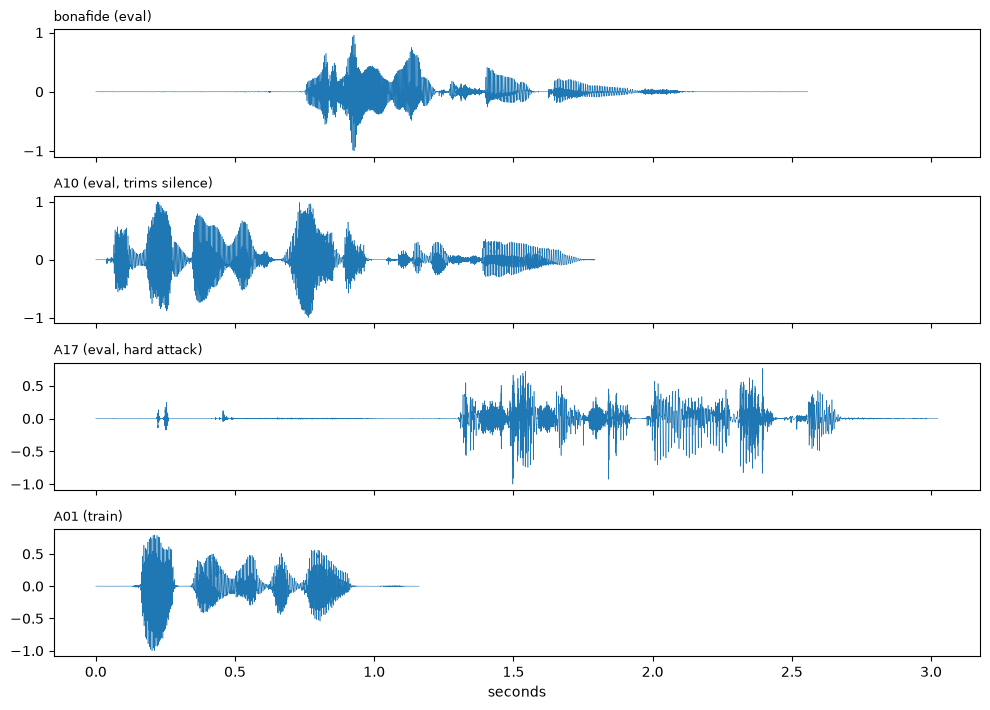

In [4]:
fig, axes = plt.subplots(len(wave), 1, figsize=(10, 1.8 * len(wave)), sharex=True)
for ax, (name, x) in zip(axes, wave.items(), strict=True):
    t = np.arange(len(x)) / SR
    ax.plot(t, x, lw=0.4)
    ax.set_title(name, fontsize=9, loc="left")
axes[-1].set_xlabel("seconds")
plt.tight_layout()
plt.show()

Look at the **start** of each waveform. The bona fide recording begins with about a quarter
of a second of room noise before the speech (measured leading silence 0.28), while the A10
clip starts almost straight into speech (0.02). The A17 clip has a long quiet lead-in in the
waveform, yet its measured leading silence is only 0.05: two short blips near 0.25 s end the
"leading silence" run early, a reminder that the measure is a simple energy threshold.
Remember this for section 5.

## 3 · The B02 pipeline, one step at a time

A1's front end turns a waveform into a `[frames × 60]` matrix. Here we rebuild it by hand
on one clip and check at the end that we get **exactly** what `extract_lfcc_b02` gives.
Every step mirrors a line of the official MATLAB `extract_lfcc.m`.

| Step | What it does | Why |
|---|---|---|
| Pre-emphasis 0.97 | `y[n] = x[n] − 0.97·x[n−1]` | boosts high frequencies, where synthesis artefacts often sit |
| Framing | 20 ms windows every 10 ms | speech is roughly stationary over about 20 ms |
| Hamming window | tapers each frame | reduces spectral leakage |
| 512-point fast Fourier transform (FFT) → power | 257 frequency bins per frame | what energy is at which frequency |
| 20 **linear** triangular filters | 257 bins → 20 bands, equally spaced 0–8 kHz | *linear*, not mel: keeps high-frequency detail, which the mel scale of mel-frequency cepstral coefficients (MFCC) squashes |
| log10 | compresses dynamic range | loudness differences become additive |
| Discrete cosine transform (DCT) | 20 correlated bands → 20 cepstral coefficients | decorrelates, which suits a *diagonal* GMM |
| Δ, ΔΔ | `x[t+1] − x[t−1]`, applied twice | how the spectrum *moves* over time |

In [16]:
cfg = DEFAULT_LFCC_B02_CONFIG
x = wave["A10 (eval, trims silence)"].astype(np.float64)
frame_len = int(SR * cfg["window_ms"] / 1000)  # 320 samples
hop = int(SR * cfg["hop_ms"] / 1000)  # 160 samples

# 1. pre-emphasis
y = lfilter([1.0, -cfg["preemph"]], [1.0], x)

# 2. framing, MATLAB buffer(..., 'nodelay'): the last partial frame is zero-padded
T = frame_count(len(y), frame_len, hop)
padded = np.zeros((T - 1) * hop + frame_len)
padded[: len(y)] = y
frames = np.stack([padded[t * hop : t * hop + frame_len] for t in range(T)])

# 3. symmetric Hamming window
frames = frames * np.hamming(frame_len)

# 4. power spectrum
power = np.abs(np.fft.rfft(frames, n=cfg["n_fft"], axis=1)) ** 2  # [T, 257]

# 5. linear triangular filterbank
fb = lfcc_b02_filterbank(cfg["n_filters"], cfg["n_fft"], SR)  # [20, 257]
energy = power @ fb.T  # [T, 20]

# 6. log10 (+eps, as MATLAB does), 7. DCT
log_e = np.log10(energy + np.finfo(float).eps)
static = dct(log_e, type=2, axis=1, norm="ortho")  # [T, 20]

# 8. deltas
d1 = official_deltas(static, w=3)
d2 = official_deltas(d1, w=3)
mine = np.concatenate([static, d1, d2], axis=1)

library = extract_lfcc_b02(x, SR)
print(f"{len(x)} samples -> {T} frames; by hand {mine.shape}, library {library.shape}")
print("identical to the library:", np.allclose(mine, library, atol=1e-4))

28680 samples -> 179 frames; by hand (179, 60), library (179, 60)
identical to the library: True


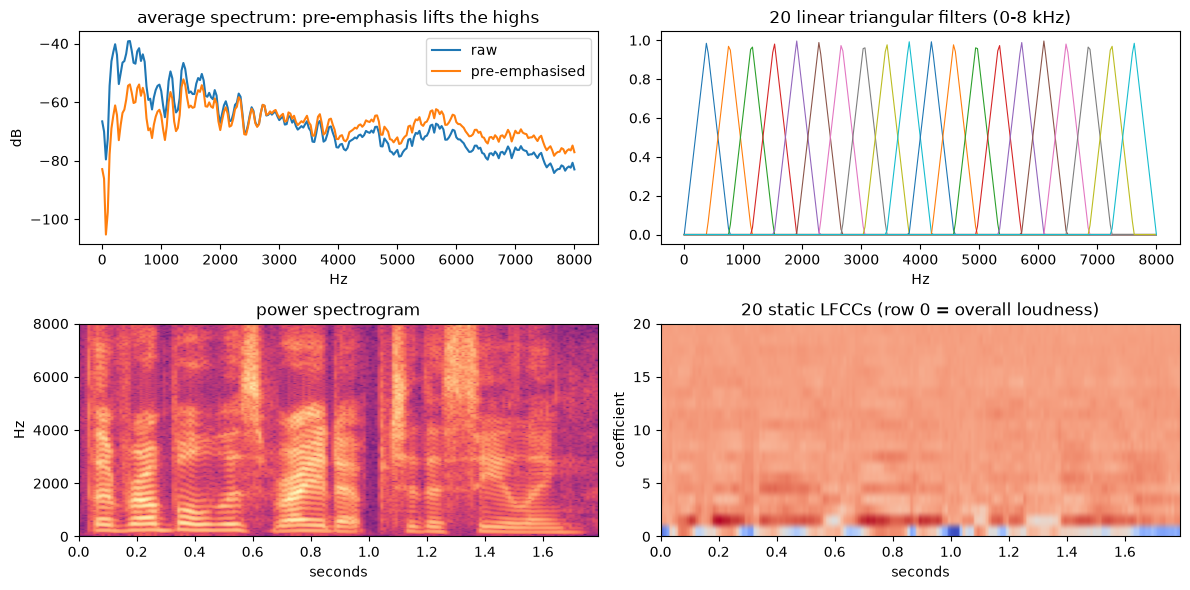

In [17]:
freqs = np.linspace(0, SR / 2, power.shape[1])
fig, axes = plt.subplots(2, 2, figsize=(12, 6))

for sig, name in [(x, "raw"), (y, "pre-emphasised")]:
    f_w, p_w = welch(sig, fs=SR, nperseg=512)
    axes[0, 0].plot(f_w, 10 * np.log10(p_w + 1e-20), label=name)
axes[0, 0].set(title="average spectrum: pre-emphasis lifts the highs", xlabel="Hz", ylabel="dB")
axes[0, 0].legend()

for f in fb:
    axes[0, 1].plot(freqs, f, lw=0.8)
axes[0, 1].set(title="20 linear triangular filters (0-8 kHz)", xlabel="Hz")

axes[1, 0].imshow(
    10 * np.log10(power.T + 1e-12),
    origin="lower",
    aspect="auto",
    extent=[0, T / 100, 0, SR / 2],
    cmap="magma",
)
axes[1, 0].set(title="power spectrogram", xlabel="seconds", ylabel="Hz")

axes[1, 1].imshow(
    static.T, origin="lower", aspect="auto", extent=[0, T / 100, 0, 20], cmap="coolwarm"
)
axes[1, 1].set(
    title="20 static LFCCs (row 0 = overall loudness)", xlabel="seconds", ylabel="coefficient"
)
plt.tight_layout()
plt.show()

The stored run rebuilds the **A10** clip (28,680 samples → 179 frames) and the hand-built
matrix matches the library exactly. Its spectrogram shows speech from the very first frames,
with no quiet lead-in, because A10 starts straight into speech.

**Try:** change `x = wave[...]` in the first cell of this section to the bona fide or A17
clip and re-run both cells. What changes in the spectrogram and the LFCC image?

## 4 · Bona fide vs spoof in feature space

A GMM models the **distribution of frames**. Before training one, look at whether the
frames' distributions differ at all. We take a random sample of 150 train clips per class
and compare the mean and spread of each static coefficient over all their frames.

{'bonafide': (50348, 60), 'spoof': (53290, 60)}


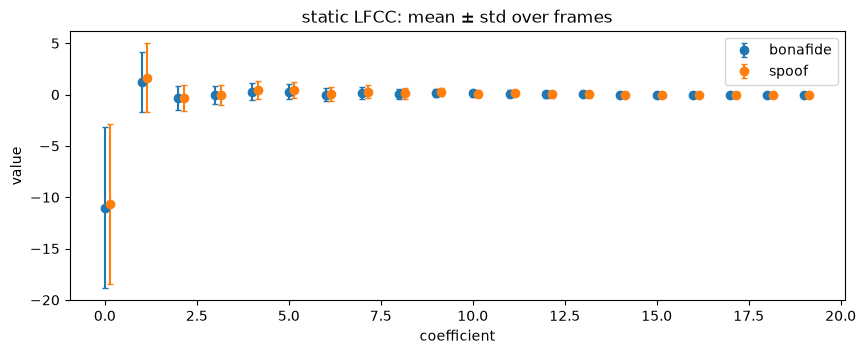

In [7]:
N_PER_CLASS = 150  # knob: more clips = smoother curves, slower cell


def features_for(rows, silence_mode="raw", cfg_override=None):
    # One [T, D] feature matrix per clip (whole utterance, as B02 does).
    out = []
    for path in rows.path:
        x, _ = load_audio(path, target_sr=SR)
        x = preprocess(x, SR, silence_mode=silence_mode, crop_seconds=None)
        out.append(extract_lfcc_b02(x, SR, cfg_override))
    return out


train = man["train"]
samp = {
    lab: train[train.label == lab].sample(N_PER_CLASS, random_state=SEED)
    for lab in ["bonafide", "spoof"]
}
feats = {lab: features_for(rows) for lab, rows in samp.items()}
frames = {lab: np.concatenate(f) for lab, f in feats.items()}
print({lab: f.shape for lab, f in frames.items()})

fig, ax = plt.subplots(figsize=(10, 3.5))
for lab, f in frames.items():
    m, s = f[:, :20].mean(0), f[:, :20].std(0)
    ax.errorbar(
        np.arange(20) + (0.15 if lab == "spoof" else 0), m, yerr=s, fmt="o", capsize=2, label=lab
    )
ax.set(title="static LFCC: mean ± std over frames", xlabel="coefficient", ylabel="value")
ax.legend()
plt.show()

The stored run pools 50,348 bona fide and 53,290 spoof frames. The error bars (± one standard
deviation over frames) overlap almost completely, so **no single coefficient separates the
classes**. The GMM works on the *joint* 60-dimensional shape of the frame cloud, and adds up
small differences over hundreds of frames per clip. That is why a per-utterance *average*
log-likelihood ratio (LLR) can work even when individual coefficients look alike.

## 5 · The silence shortcut (the project's key caveat)

The project's leakage audit (notebook 01) measured that **leading silence alone** predicts
bona fide vs spoof with an area under the curve (AUC) of 0.837. A detector can learn "no
silence at the start → fake" without learning anything about synthesis. We check it on a
650-clip stratified eval sample.

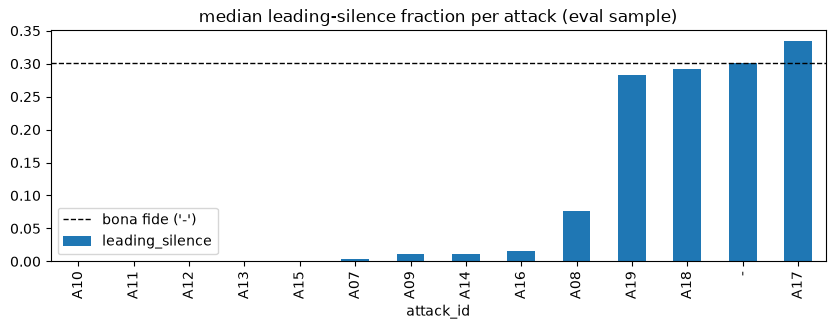

In [8]:
N_EVAL_SAMPLE = 650  # stratified over bona fide + A07-A19

ev = stratified_subset(man["eval"], n=N_EVAL_SAMPLE, seed=SEED)
lead = []
for path in ev.path:
    x, _ = load_audio(path, target_sr=SR)
    lead.append(silence_ratio(x)["leading"])
ev = ev.assign(leading_silence=lead)

med = ev.groupby("attack_id").leading_silence.median().sort_values()
ax = med.plot.bar(figsize=(10, 3), title="median leading-silence fraction per attack (eval sample)")
ax.axhline(med["-"], color="k", ls="--", lw=1, label="bona fide ('-')")
ax.legend()
plt.show()

In this sample, five unseen attacks (A10, A11, A12, A13, A15) have a median leading-silence
fraction of about **0**, and A07, A09, A14 and A16 are below 0.02; those generators hand a
detector a free shortcut. A17, A18 and A19 sit close to the bona fide median (about 0.30), so
they don't. In section 7 you'll *trim* silence at test time and see how much of the mini-A1's
performance depended on it.

## 6 · A mini A1, in about a minute

This is the same recipe as the real A1, shrunk down:

- **Real A1:** all 25,380 train clips, two 512-component GMMs, 10 expectation-maximisation
  (EM) iterations.
- **Mini A1:** 300 clips per class, 32 components, 10 iterations.

**Training.** Fit one GMM on all frames from bona fide clips and another on all frames
from spoof clips.

**Scoring.** For a test clip, each frame gets a log-likelihood under both GMMs. The
score is the mean over frames of `log p(frame | bona fide) − log p(frame | spoof)`.
**Higher means more bona fide.**

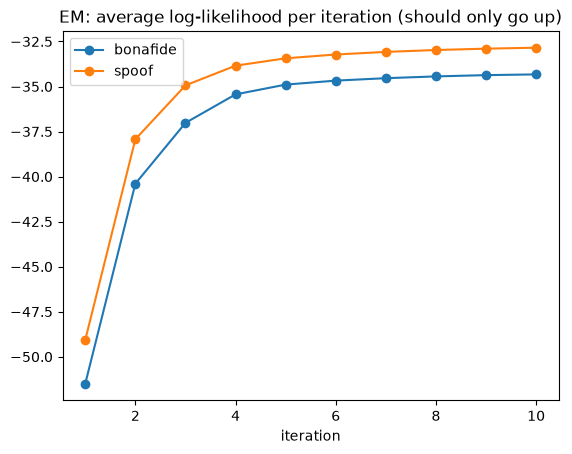

In [9]:
def train_mini_a1(n_clips=300, n_components=32, n_iter=10, use_deltas=True, cfg_override=None):
    gmms, hist = {}, {}
    for lab in ["bonafide", "spoof"]:
        rows = train[train.label == lab].sample(n_clips, random_state=SEED)
        f = np.concatenate(features_for(rows, cfg_override=cfg_override))
        if not use_deltas:
            f = f[:, : f.shape[1] // 3]
        g = DiagGMM(n_components, f.shape[1])
        hist[lab] = g.fit_em(f, n_iter=n_iter, seed=SEED)
        gmms[lab] = g
    return gmms, hist


def score_rows(gmms, rows, silence_mode="raw", use_deltas=True, cfg_override=None):
    scores = []
    for f in features_for(rows, silence_mode=silence_mode, cfg_override=cfg_override):
        if not use_deltas:
            f = f[:, : f.shape[1] // 3]
        scores.append(score_llr(gmms["bonafide"], gmms["spoof"], f))
    return rows.assign(score=scores)


gmms, hist = train_mini_a1()
for lab, h in hist.items():
    plt.plot(range(1, len(h) + 1), h, marker="o", label=lab)
plt.title("EM: average log-likelihood per iteration (should only go up)")
plt.xlabel("iteration")
plt.legend()
plt.show()

PLAYGROUND ONLY  dev EER 9.9%  (known attacks A01-A06)
PLAYGROUND ONLY  eval EER 16.6%  (unseen attacks A07-A19)


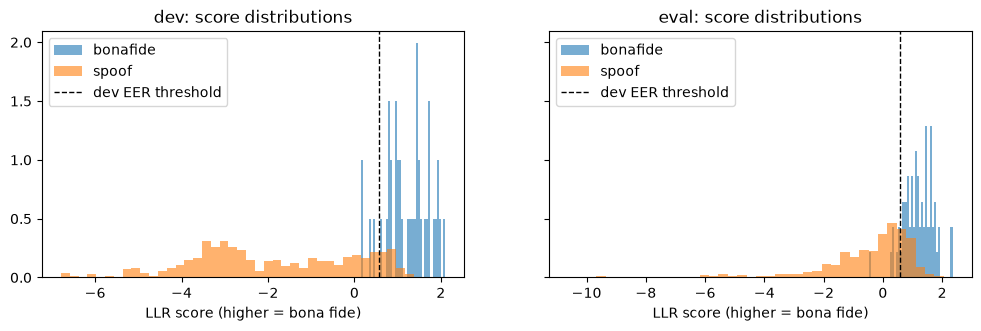

In [10]:
dev_s = score_rows(gmms, stratified_subset(man["dev"], n=400, seed=SEED))
eval_s = score_rows(gmms, ev)  # the same stratified eval sample as section 5


def eer(df):
    return compute_eer(df.score, df.label, higher_is_spoof=False)


dev_eer, dev_thr = eer(dev_s)
eval_eer, _ = eer(eval_s)
print(f"PLAYGROUND ONLY  dev EER {dev_eer:.1%}  (known attacks A01-A06)")
print(f"PLAYGROUND ONLY  eval EER {eval_eer:.1%}  (unseen attacks A07-A19)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, (name, df) in zip(axes, [("dev", dev_s), ("eval", eval_s)], strict=True):
    for lab in ["bonafide", "spoof"]:
        ax.hist(df[df.label == lab].score, bins=40, alpha=0.6, density=True, label=lab)
    ax.axvline(dev_thr, color="k", ls="--", lw=1, label="dev EER threshold")
    ax.set(title=f"{name}: score distributions", xlabel="LLR score (higher = bona fide)")
    ax.legend()
plt.show()

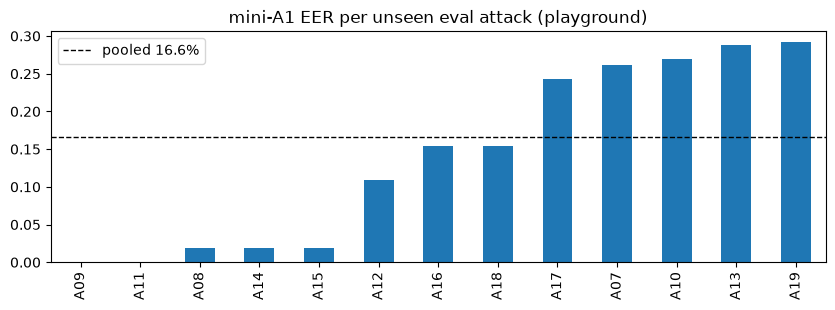

In [11]:
pa = per_attack_eer(eval_s.score, eval_s.label, eval_s.attack_id, higher_is_spoof=False)
per_attack = pd.Series(pa["per_attack"]).sort_values()
ax = per_attack.plot.bar(figsize=(10, 3), title="mini-A1 EER per unseen eval attack (playground)")
ax.axhline(pa["pooled_eer"], color="k", ls="--", lw=1, label=f"pooled {pa['pooled_eer']:.1%}")
ax.legend()
plt.show()

**What the stored run shows (playground numbers).** The mini-A1 scores 9.9 % EER on a dev
sample (known attacks) and 16.6 % on the eval sample (unseen attacks). Per attack, A09 and A11
are near 0 %, A08, A14 and A15 about 2 %, while A07, A10, A13 and A19 are the hardest (about
26-29 %).

Compare this bar chart with section 5's silence chart. The link is not one-to-one: A11 trims
silence and is easy, but A10 and A13 also trim silence and are among the hardest, and A19 has
bona-fide-like silence and is hard too. So silence is not the only thing the mini-A1 uses;
the trimming test in section 7 measures how much it leans on it.

For reference only (literature, never put in the same column as our runs): the official
B02 scored **8.09% EER** on the full eval set (arXiv 1904.05441, Table 1).

## 7 · Play with the knobs

Each experiment below changes **one** thing and re-scores the same clips. They're
written as small functions so you can run them in any order.

| Knob | Question it answers |
|---|---|
| `silence_mode="trimmed"` at test time | How much did the model lean on silence? |
| `use_deltas=False` | Do the dynamics (Δ, ΔΔ) matter, or just the spectral shape? |
| `n_components` 4 / 32 / 128 | How detailed does the frame distribution model need to be? |
| `n_clips` 50 / 300 / 1000 | How much does more training data help? |
| `cfg_override={"n_filters": 40}` | Finer frequency resolution → more (or less) useful detail? |

eval EER raw 16.6%  ->  trimmed 30.3%


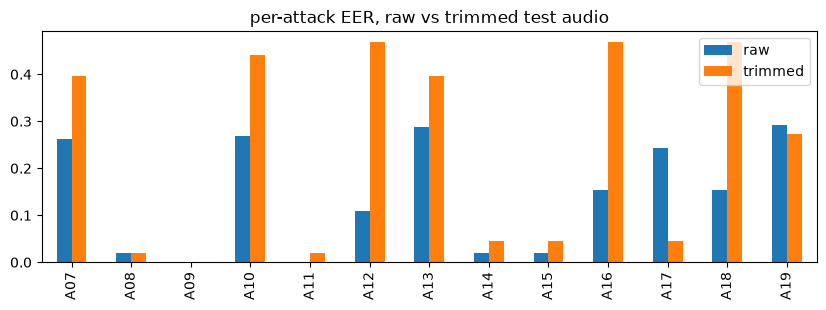

In [12]:
# 7a. Trim silence at TEST time only: same trained GMMs, same clips.
eval_trim = score_rows(gmms, ev, silence_mode="trimmed")
print(f"eval EER raw {eer(eval_s)[0]:.1%}  ->  trimmed {eer(eval_trim)[0]:.1%}")
pa_t = per_attack_eer(eval_trim.score, eval_trim.label, eval_trim.attack_id, higher_is_spoof=False)
pd.DataFrame({"raw": pa["per_attack"], "trimmed": pa_t["per_attack"]}).plot.bar(
    figsize=(10, 3), title="per-attack EER, raw vs trimmed test audio"
)
plt.show()

In [13]:
# 7b. Static only (20 dims) vs static + deltas (60 dims).
g_static, _ = train_mini_a1(use_deltas=False)
print(
    f"eval EER with deltas {eer(eval_s)[0]:.1%}   static only "
    f"{eer(score_rows(g_static, ev, use_deltas=False))[0]:.1%}"
)

eval EER with deltas 16.6%   static only 16.5%


In [14]:
# 7c. Model size. Bigger isn't free: each extra component needs data to estimate it.
for k in [4, 32, 128]:
    g_k, _ = train_mini_a1(n_components=k)
    print(f"K={k:4d}  eval EER {eer(score_rows(g_k, ev))[0]:.1%}")

K=   4  eval EER 19.6%
K=  32  eval EER 16.6%
K= 128  eval EER 15.1%


In [15]:
# 7d. Your turn: combine knobs, e.g. more filters and more training clips.
g_mine, _ = train_mini_a1(n_clips=300, n_components=32, cfg_override={"n_filters": 40})
print(f"eval EER {eer(score_rows(g_mine, ev, cfg_override={'n_filters': 40}))[0]:.1%}")

eval EER 9.1%


## 8 · What the stored run shows, and questions to think about

**Measured in this run (playground numbers, about 50 eval clips per attack, so per-attack
values are noisy):**

- **Trimming silence at test time** raises the pooled eval EER from 16.6 % to 30.3 %. A12, A16
  and A18 rise most (from about 11-15 % to about 47 %), while A17 drops from about 24 % to
  about 5 %. One reading (a hypothesis): A17's bona-fide-like silence earned bona fide credit
  that disappears once trimmed.
- **Deltas** make no difference on this sample (16.6 % with Δ/ΔΔ, 16.5 % static only).
- **Model size:** 4 components 19.6 %, 32 components 16.6 %, 128 components 15.1 %.
- **40 filters instead of 20** (same 300 clips, 32 components) lowers eval EER to 9.1 %.

**Questions**

1. **Known vs unseen:** why is dev EER so much lower than eval EER? (Hint: which attacks
   are in each?)
2. **Silence:** after trimming at test time, which attacks got harder? Does that match
   section 5?
3. **What's the GMM really modelling?** It never sees time order beyond Δ/ΔΔ, only a cloud
   of frames. What kinds of artefacts can it catch, and what can't it?
4. **Why linear filters?** LFCC spaces filters evenly up to 8 kHz; MFCC (mel) packs them
   into low frequencies. Where would vocoder artefacts show up?
5. **Why 512 components in the real A1?** With 25k clips (about 8.7M frames), what does a
   larger model buy, and what does it cost in memory and time?

**Next:** notebook **10** runs the real A1, and its numbers go into
`runs/REGISTRY.md`.